<a href="https://colab.research.google.com/github/mvanamali-27/DIP-rPPG/blob/main/notebooks/03_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
if os.path.isdir("DIP-rPPG"):
    !cd DIP-rPPG && git pull -q
else:
    !git clone -q https://github.com/mvanamali-27/DIP-rPPG.git

In [ ]:
import sys, importlib
if "DIP-rPPG/src" not in sys.path:
    sys.path.append("DIP-rPPG/src")
import numpy as np
import matplotlib.pyplot as plt
import config, data, extract_all, windows, evaluate, cnn
import signal_proc as sp

for module in (config, data, sp, extract_all, windows, evaluate, cnn):
    importlib.reload(module)

In [ ]:
dataset = windows.build_dataset() #run only once!!!!

KeyboardInterrupt: 

In [ ]:
ds = windows.load_dataset()
for key, value in ds.items():
    print(f"{key:10s} shape {str(value.shape):15s} {value.dtype}")
print(f"\n{len(np.unique(ds['subject']))} subjects, {len(ds['bpm'])} windows, "
      f"true heart rates from {ds['bpm'].min():.0f} to {ds['bpm'].max():.0f} bpm")
for name in ["bpm_green", "bpm_pos"]:
    err = ds[name] - ds["bpm"]
    print(f"{name:10s} MAE {np.mean(np.abs(err)):.2f} | RMSE {np.sqrt(np.mean(err ** 2)):.2f} | "
          f"within 5 bpm {np.mean(np.abs(err) <= 5):.0%}")

rgb        shape (1129, 300, 3)  float32
pulse      shape (1129, 300)     float32
bpm        shape (1129,)         float64
bpm_pos    shape (1129,)         float64
bpm_green  shape (1129,)         float64
t          shape (1129,)         float64
subject    shape (1129,)         <U10

21 subjects, 1129 windows, true heart rates from 63 to 134 bpm
bpm_green  MAE 3.35 | RMSE 11.61 | within 5 bpm 91%
bpm_pos    MAE 0.68 | RMSE 2.28 | within 5 bpm 99%


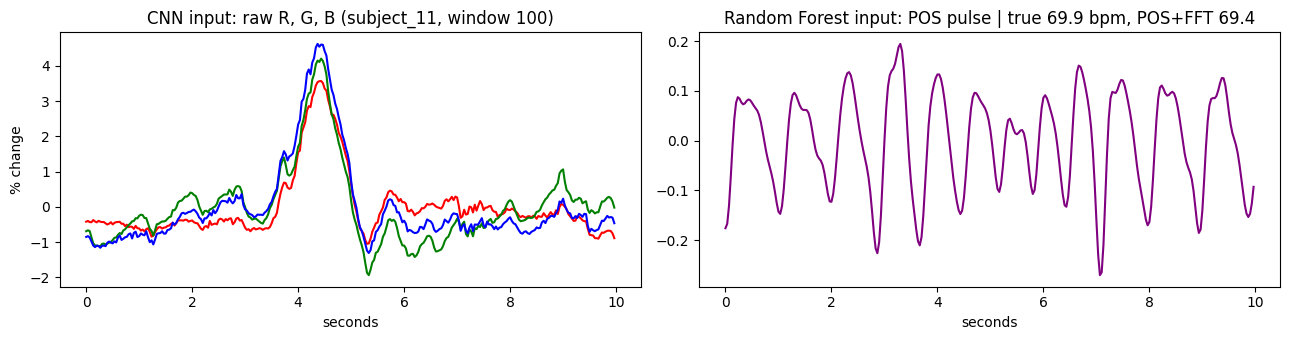

In [ ]:
i = 100
sec = np.arange(windows.WINDOW_LEN) / windows.FPS_OUT
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for c, color in enumerate(["red", "green", "blue"]):
    x = ds["rgb"][i, :, c]
    ax[0].plot(sec, 100 * (x / x.mean() - 1), color=color)       # % change, so the 3 colors share one scale
ax[0].set_title(f"CNN input: raw R, G, B ({ds['subject'][i]}, window {i})")
ax[0].set_xlabel("seconds"); ax[0].set_ylabel("% change")
ax[1].plot(sec, ds["pulse"][i], color="purple")
ax[1].set_title(f"Random Forest input: POS pulse | true {ds['bpm'][i]:.1f} bpm, POS+FFT {ds['bpm_pos'][i]:.1f}")
ax[1].set_xlabel("seconds"); plt.tight_layout(); plt.show()

In [ ]:
from sklearn.dummy import DummyRegressor

ds = windows.load_dataset()
y, subj = ds["bpm"], ds["subject"]

# The floor: a "model" given NO information that always guesses the average heart
# rate of the people it trained on. Anything useful has to beat this.
no_info = np.zeros((len(y), 1))
pred_floor = evaluate.loso_predict(lambda: DummyRegressor(strategy="mean"), no_info, y, subj)

print("\nSCORECARD (Leave-One-Subject-Out)\n")
scores = {}
scores["guess the average"] = evaluate.summary("guess the average", y, pred_floor, subj)
scores["green + FFT"] = evaluate.summary("green + FFT", y, ds["bpm_green"], subj)
scores["POS + FFT"] = evaluate.summary("POS + FFT", y, ds["bpm_pos"], subj)

  [1/21] tested on subject_10: MAE 9.15
  [2/21] tested on subject_11: MAE 27.01
  [3/21] tested on subject_13: MAE 6.79
  [4/21] tested on subject_14: MAE 13.51
  [5/21] tested on subject_15: MAE 22.58
  [6/21] tested on subject_16: MAE 28.64
  [7/21] tested on subject_17: MAE 5.72
  [8/21] tested on subject_18: MAE 4.45
  [9/21] tested on subject_19: MAE 14.22
  [10/21] tested on subject_2: MAE 7.76
  [11/21] tested on subject_20: MAE 10.94
  [12/21] tested on subject_21: MAE 23.52
  [13/21] tested on subject_22: MAE 13.00
  [14/21] tested on subject_23: MAE 4.45
  [15/21] tested on subject_3: MAE 8.25
  [16/21] tested on subject_4: MAE 1.99
  [17/21] tested on subject_5: MAE 13.40
  [18/21] tested on subject_6: MAE 8.93
  [19/21] tested on subject_7: MAE 14.39
  [20/21] tested on subject_8: MAE 25.50
  [21/21] tested on subject_9: MAE 35.32

SCORECARD (Leave-One-Subject-Out)

guess the average  MAE 14.58 | RMSE 17.89 | within 5 bpm  21% | per person: avg 14.26, median 13.00, worst 3

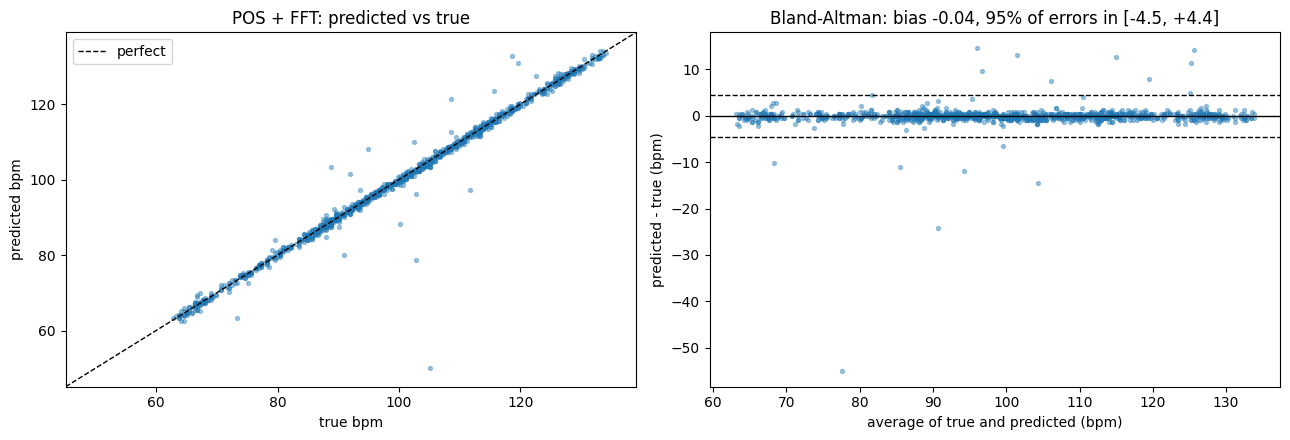

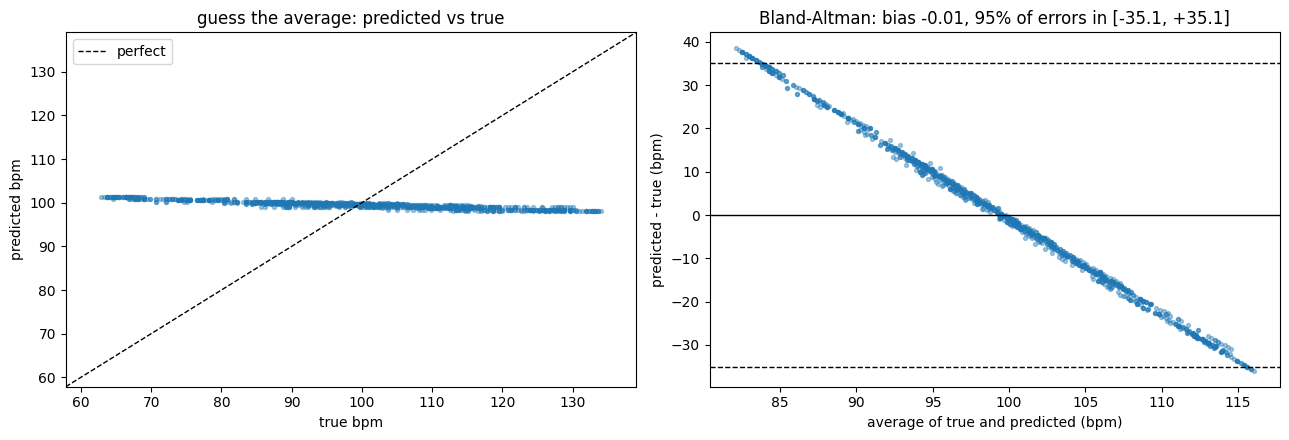

In [ ]:
evaluate.plot_agreement("POS + FFT", y, ds["bpm_pos"])
evaluate.plot_agreement("guess the average", y, pred_floor)

In [ ]:
print("training on:", cnn.DEVICE)

training on: cuda


trained in 19 s on 1073 windows | subject_10: CNN MAE 1.75, POS MAE 0.36


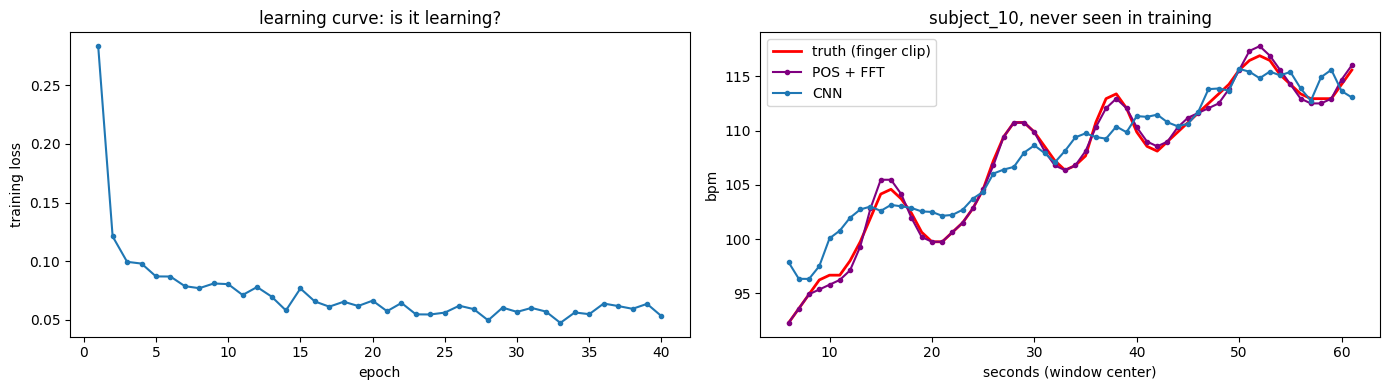

In [ ]:
import time
test = subj == "subject_10"
t0 = time.time()
model = cnn.CNNRegressor().fit(ds["rgb"][~test], y[~test])
pred10 = model.predict(ds["rgb"][test])
print(f"trained in {time.time() - t0:.0f} s on {(~test).sum()} windows | "
      f"subject_10: CNN MAE {np.mean(np.abs(pred10 - y[test])):.2f}, "
      f"POS MAE {np.mean(np.abs(ds['bpm_pos'][test] - y[test])):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(range(1, len(model.losses) + 1), model.losses, ".-")
ax[0].set(xlabel="epoch", ylabel="training loss", title="learning curve: is it learning?")
ax[1].plot(ds["t"][test], y[test], "r-", lw=2, label="truth (finger clip)")
ax[1].plot(ds["t"][test], ds["bpm_pos"][test], ".-", color="purple", label="POS + FFT")
ax[1].plot(ds["t"][test], pred10, "o-", color="tab:blue", ms=3, label="CNN")
ax[1].set(xlabel="seconds (window center)", ylabel="bpm", title="subject_10, never seen in training")
ax[1].legend(); plt.tight_layout(); plt.show()

  [1/21] tested on subject_10: MAE 1.81
  [2/21] tested on subject_11: MAE 6.12
  [3/21] tested on subject_13: MAE 1.22
  [4/21] tested on subject_14: MAE 0.99
  [5/21] tested on subject_15: MAE 2.85
  [6/21] tested on subject_16: MAE 2.70
  [7/21] tested on subject_17: MAE 1.65
  [8/21] tested on subject_18: MAE 2.40
  [9/21] tested on subject_19: MAE 1.97
  [10/21] tested on subject_2: MAE 5.73
  [11/21] tested on subject_20: MAE 2.61
  [12/21] tested on subject_21: MAE 1.68
  [13/21] tested on subject_22: MAE 2.79
  [14/21] tested on subject_23: MAE 1.79
  [15/21] tested on subject_3: MAE 5.93
  [16/21] tested on subject_4: MAE 1.94
  [17/21] tested on subject_5: MAE 1.57
  [18/21] tested on subject_6: MAE 1.68
  [19/21] tested on subject_7: MAE 1.71
  [20/21] tested on subject_8: MAE 4.89
  [21/21] tested on subject_9: MAE 3.28

201 s in total

CNN (raw RGB)      MAE  2.66 | RMSE  3.93 | within 5 bpm  88% | per person: avg  2.73, median  1.97, worst  6.12


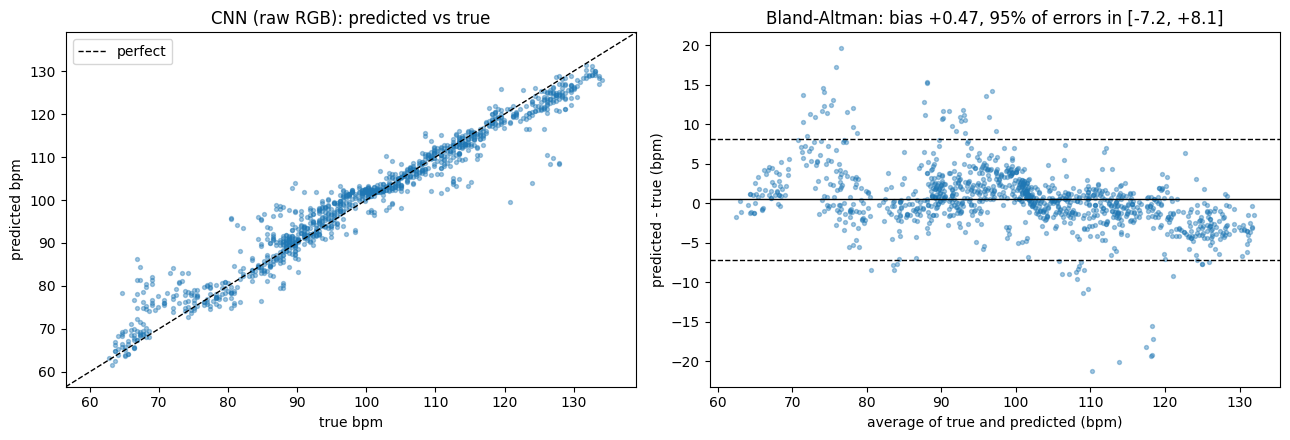

In [ ]:
t0 = time.time()
pred_cnn = evaluate.loso_predict(lambda: cnn.CNNRegressor(), ds["rgb"], y, subj)
print(f"\n{time.time() - t0:.0f} s in total\n")
scores["CNN (raw RGB)"] = evaluate.summary("CNN (raw RGB)", y, pred_cnn, subj)
evaluate.plot_agreement("CNN (raw RGB)", y, pred_cnn)
np.save(config.DATA_DIR / "pred_cnn.npy", pred_cnn)     # keep the predictions, so the report never needs a retrain

In [ ]:
print(f"{'method':18s} {'MAE':>6s} {'RMSE':>6s} {'within 5':>9s} {'worst person':>13s}")
for name, s in sorted(scores.items(), key=lambda kv: kv[1]["MAE"], reverse=True):
    print(f"{name:18s} {s['MAE']:6.2f} {s['RMSE']:6.2f} {s['within5']:9.0%} {s['person_worst']:13.2f}")

method                MAE   RMSE  within 5  worst person
guess the average   14.58  17.89       21%         35.32
green + FFT          3.35  11.61       91%         15.10
CNN (raw RGB)        2.66   3.93       88%          6.12
POS + FFT            0.68   2.28       99%          1.94
